# 🚦 ĐỀ TÀI 29: TIMED GATES / TRAFFIC-LIGHT GRID
> **Cấu trúc Notebook:**  
> 1. **Phần 1:** Thiết kế MDP, Trực quan hóa 3 Map & Cơ chế Cổng / Vé Pass  
> 2. **Phần 2:** Cài đặt & Bảng so sánh tổng hợp 9 Thuật toán Tabular RL  
> 3. **Phần 3:** Kịch bản Thực nghiệm & Phân tích chuyên sâu (Tradeoff Wait vs Đi vòng, Đổi Reward, 5 Random Seeds, Failure Cases)

# =====================================================================
# PHẦN 1: MÔI TRƯỜNG TIMED GATES & 3 CẤU HÌNH MAP 
# =====================================================================

In [5]:
%matplotlib inline
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from env import make_env, UP, DOWN, LEFT, RIGHT, WAIT, ACTION_NAMES
from visualize import plot_3_maps, draw_env, plot_progression, plot_policy_grid, plot_learning_curves, plot_multi_seed_comparison
from algorithms import (
    ALL_ALGORITHMS,
    value_iteration,
    policy_iteration,
    truncated_policy_iteration,
    mc_epsilon_greedy,
    sarsa,
    q_learning,
    n_step_sarsa,
)
from experiments import (
    run_wait_vs_detour_analysis,
    run_reward_tuning_analysis,
    run_multi_seed_experiment,
    run_failure_case_analysis,
)


### 1.1. Trực Quan Hóa 3 Bản Đồ Tích Hợp 4 Setting Bắt Buộc

| Bản đồ | Kích thước | Setting tích hợp | Chu kỳ chung $P$ | Vé Pass | Không gian trạng thái $|S| = H \times W \times P \times \text{Pass}$ |

| :--- | :--- | :--- | :--- | :--- | :--- |
| **Map 1 (Dễ)** | 4×4 | **Setting 1 + 3:** 1 cổng chu kỳ 2 + đường vòng, không pass | $P = 2$ | 0 | $4 \times 4 \times 2 \times 1 = \mathbf{32\text{ states}}$ |

| **Map 2 (Trung bình)** | 5×5 | **Setting 2 + 3:** 2 cổng chu kỳ 2 & 3 + ô chờ + đường vòng | $P = \text{LCM}(2,3) = 6$ | 0 | $5 \times 5 \times 6 \times 1 = \mathbf{150\text{ states}}$ |

| **Map 3 (Khó)** | 6×6 | **Setting 2 + 3 + 4:** 3 cổng chu kỳ 2, 3, 2 + đường vòng + **1 vé Pass** | $P = 6$ | 1 | $6 \times 6 \times 6 \times 2 = \mathbf{432\text{ states}}$ |

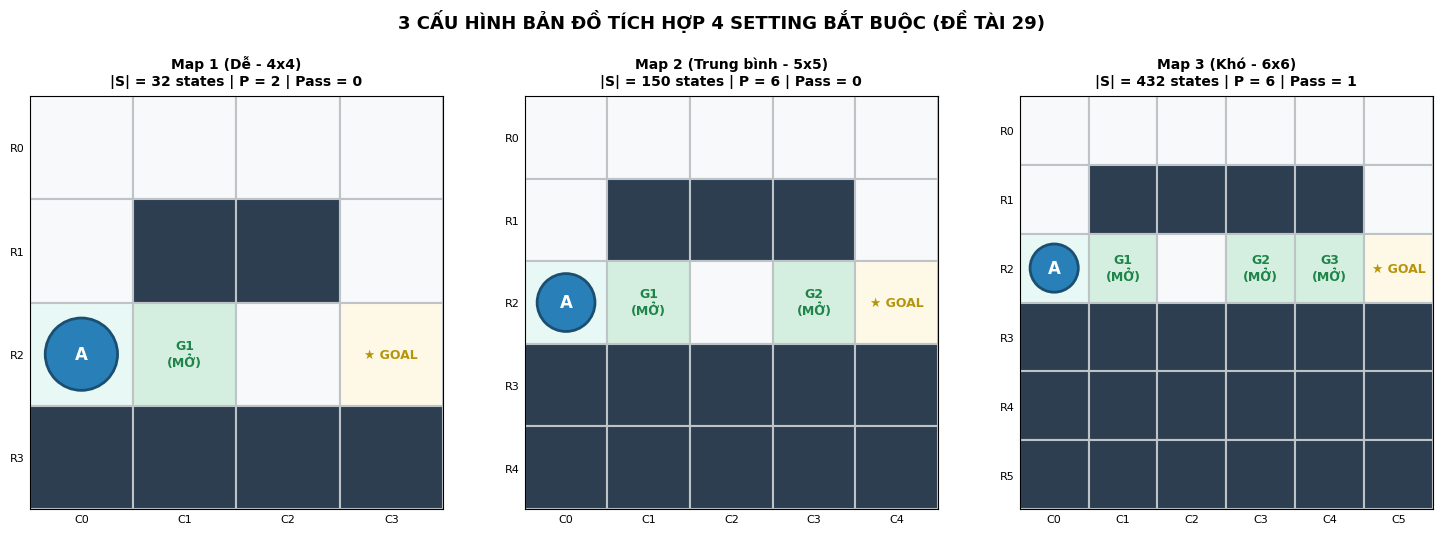

In [6]:
# Hiển thị 3 bản đồ màu sắc cạnh nhau để so sánh kích thước và vị trí cổng
fig = plot_3_maps()
plt.show()

### 1.2. Thử Nghiệm Diễn Biến: Hành Động WAIT (Map 1) & Dùng Vé Pass (Map 3)

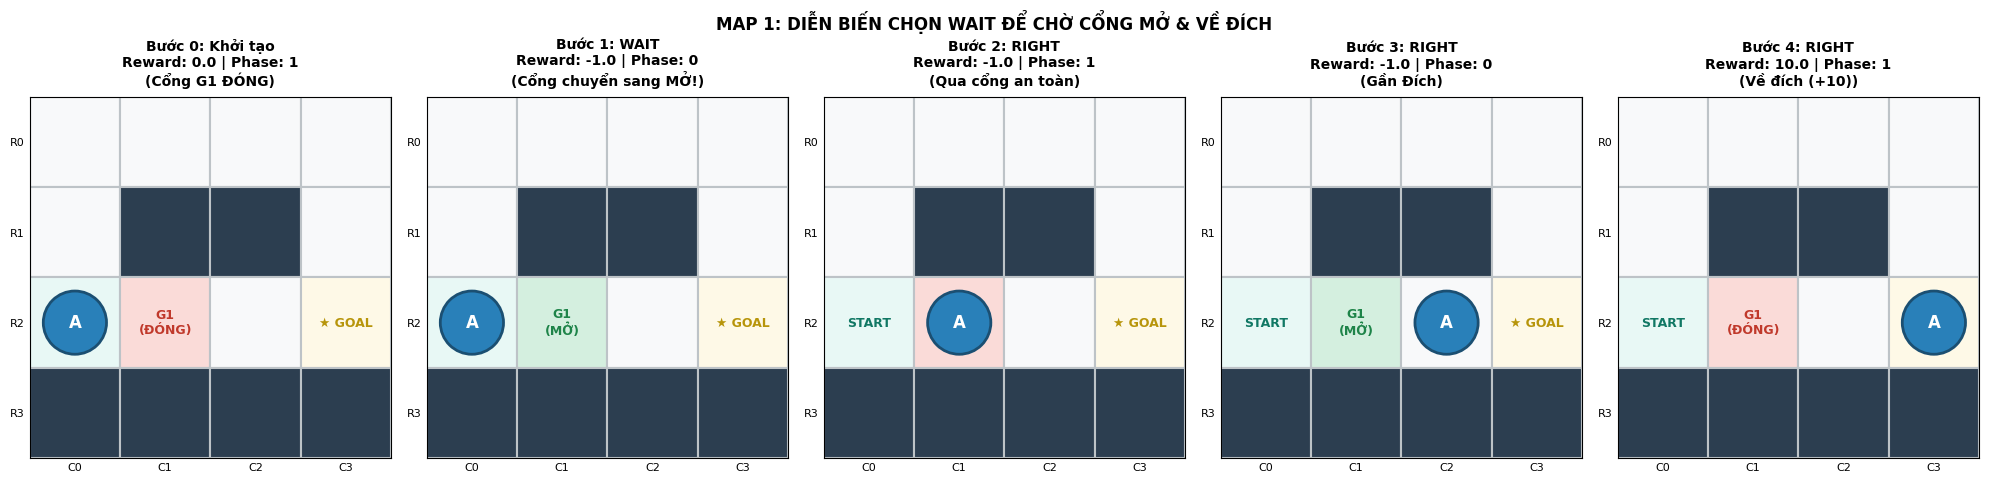

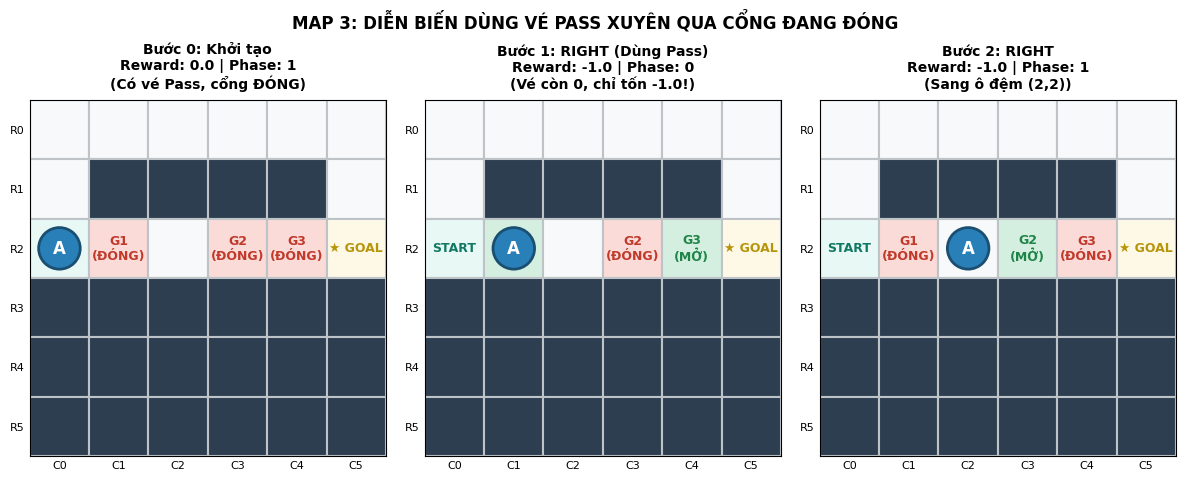

In [7]:
# 1. Map 1: Agent chọn WAIT khi cổng đóng rồi đi qua
env1 = make_env("map1")
env1.reset(options={"start_phase": 1})
hist1 = [{"env": copy.deepcopy(env1), "action_name": "Khởi tạo", "reward": 0.0, "phase": 1, "note": "Cổng G1 ĐÓNG"}]
_, r1, _, _, _ = env1.step(WAIT)
hist1.append({"env": copy.deepcopy(env1), "action_name": "WAIT", "reward": r1, "phase": 0, "note": "Cổng chuyển sang MỞ!"})
_, r2, _, _, _ = env1.step(RIGHT)
hist1.append({"env": copy.deepcopy(env1), "action_name": "RIGHT", "reward": r2, "phase": 1, "note": "Qua cổng an toàn"})
_, r3, _, _, _ = env1.step(RIGHT)
hist1.append({"env": copy.deepcopy(env1), "action_name": "RIGHT", "reward": r3, "phase": 0, "note": "Gần Đích"})
_, r4, _, _, _ = env1.step(RIGHT)
hist1.append({"env": copy.deepcopy(env1), "action_name": "RIGHT", "reward": r4, "phase": 1, "note": "Về đích (+10)"})

plot_progression(hist1, main_title="MAP 1: DIỄN BIẾN CHỌN WAIT ĐỂ CHỜ CỔNG MỞ & VỀ ĐÍCH")
plt.show()

# 2. Map 3: Dùng vé Pass đi xuyên qua cổng đang đóng
env3 = make_env("map3")
env3.reset(options={"start_phase": 1, "initial_pass": 1})
hist3 = [{"env": copy.deepcopy(env3), "action_name": "Khởi tạo", "reward": 0.0, "phase": 1, "note": "Có vé Pass, cổng ĐÓNG"}]
_, rp1, _, _, _ = env3.step(RIGHT)
hist3.append({"env": copy.deepcopy(env3), "action_name": "RIGHT (Dùng Pass)", "reward": rp1, "phase": 0, "note": "Vé còn 0, chỉ tốn -1.0!"})
_, rp2, _, _, _ = env3.step(RIGHT)
hist3.append({"env": copy.deepcopy(env3), "action_name": "RIGHT", "reward": rp2, "phase": 1, "note": "Sang ô đệm (2,2)"})

plot_progression(hist3, main_title="MAP 3: DIỄN BIẾN DÙNG VÉ PASS XUYÊN QUA CỔNG ĐANG ĐÓNG")
plt.show()

# =====================================================================
# PHẦN 2: CÀI ĐẶT & SO SÁNH 7 THUẬT TOÁN TABULAR RL
# =====================================================================

### 2.1. Nhóm 1: Model-Based / Quy Hoạch Động (Value Iteration, Policy Iteration, Truncated PI)
Chạy trên **Map 1**, so sánh số vòng lặp và trực quan hóa **Lưới chính sách tối ưu $\pi^*$ (Mũi tên $\uparrow, \downarrow, \leftarrow, \rightarrow, \text{W}$)** theo từng Phase!

,Thuật toán,Số vòng lặp,CPU Time (ms),V*(Start phase 0)
0,Value Iteration,6,7.10,6.20
1,Policy Iteration,6,24.59,6.20
2,Truncated PI (k=5),7,13.41,6.20


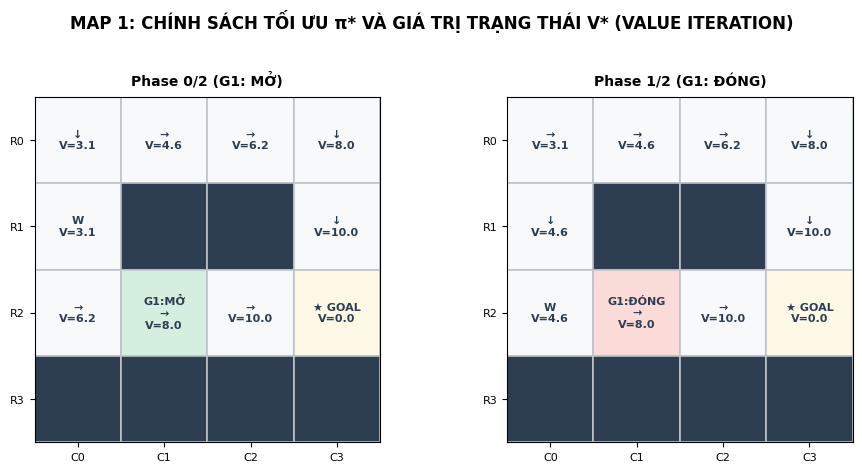

In [8]:
env_dp = make_env("map1")

t0 = time.time(); res_vi = value_iteration(env_dp, gamma=0.9); t_vi = (time.time() - t0) * 1000
t0 = time.time(); res_pi = policy_iteration(env_dp, gamma=0.9); t_pi = (time.time() - t0) * 1000
t0 = time.time(); res_tpi = truncated_policy_iteration(env_dp, gamma=0.9, max_k=5); t_tpi = (time.time() - t0) * 1000

df_dp = pd.DataFrame([
    {"Thuật toán": "Value Iteration", "Số vòng lặp": res_vi["iterations"], "CPU Time (ms)": f"{t_vi:.2f}", "V*(Start phase 0)": f"{res_vi['V'][16]:.2f}"},
    {"Thuật toán": "Policy Iteration", "Số vòng lặp": res_pi["iterations"], "CPU Time (ms)": f"{t_pi:.2f}", "V*(Start phase 0)": f"{res_pi['V'][16]:.2f}"},
    {"Thuật toán": "Truncated PI (k=5)", "Số vòng lặp": res_tpi["iterations"], "CPU Time (ms)": f"{t_tpi:.2f}", "V*(Start phase 0)": f"{res_tpi['V'][16]:.2f}"},
])
display(df_dp)

# Vẽ lưới chính sách tối ưu:
fig = plot_policy_grid(env_dp, res_vi["V"], res_vi["policy"], title="MAP 1: CHÍNH SÁCH TỐI ƯU π* VÀ GIÁ TRỊ TRẠNG THÁI V* (VALUE ITERATION)")
plt.show()

### 2.2. Nhóm 2: Monte Carlo Model-Free (MC $\varepsilon$-Greedy)

In [9]:
env_mc = make_env("map1")
res_mc_eps = mc_epsilon_greedy(env_mc, gamma=0.9, epsilon=0.1, episodes=500)

df_mc = pd.DataFrame([
    {"Thuật toán": "MC Epsilon-Greedy", "Cơ chế thăm dò": "Chính sách mềm epsilon=0.1", "V(Start phase 0)": f"{res_mc_eps['V'][16]:.2f}"},
])
display(df_mc)

,Thuật toán,Cơ chế thăm dò,V(Start phase 0)
0,MC Epsilon-Greedy,Chính sách mềm epsilon=0.1,5.53


### 2.3. Nhóm 3: Temporal-Difference (SARSA, Q-Learning, 3-step SARSA)

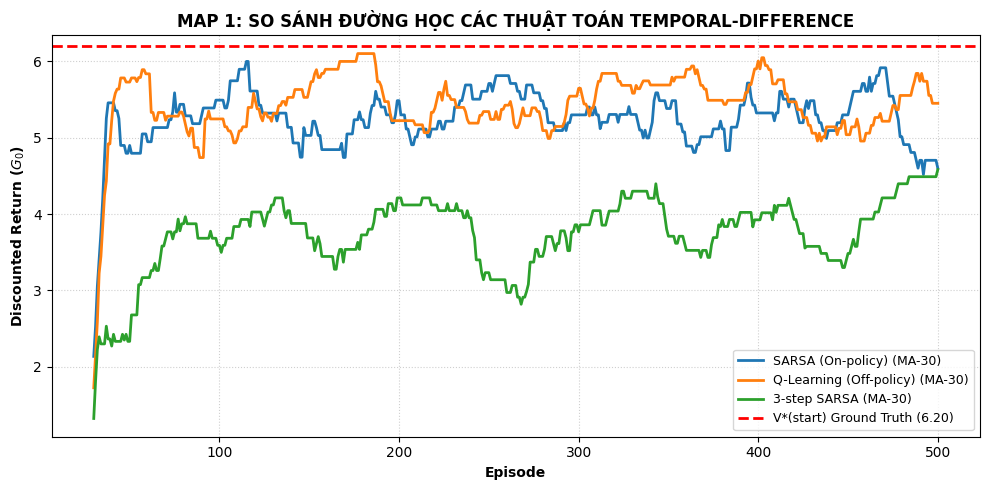

In [10]:
env_td = make_env("map1")
res_sarsa = sarsa(env_td, gamma=0.9, alpha=0.1, epsilon=0.1, episodes=500)
res_ql = q_learning(env_td, gamma=0.9, alpha=0.1, epsilon=0.1, episodes=500)
res_n_sarsa = n_step_sarsa(env_td, gamma=0.9, alpha=0.1, epsilon=0.1, n=3, episodes=500)

curves = {
    "SARSA (On-policy)": res_sarsa["history"],
    "Q-Learning (Off-policy)": res_ql["history"],
    "3-step SARSA": res_n_sarsa["history"],
}
v_star_start = res_vi["V"][16]
fig = plot_learning_curves(curves, ground_truth_v=v_star_start, window=30, title="MAP 1: SO SÁNH ĐƯỜNG HỌC CÁC THUẬT TOÁN TEMPORAL-DIFFERENCE")
plt.show()

### 2.4. Bảng Xếp Hạng Tổng Hợp Cả 7 Thuật Toán Trên Map 2 (5×5, $|S| = 150$)

In [11]:
env2 = make_env("map2")
print(f"Đang kiểm thử 7 thuật toán trên {env2.config.name}...")
results_summary = []

for name, algo_func in ALL_ALGORITHMS.items():
    t0 = time.time()
    if "MC" in name:
        res = algo_func(env2, gamma=0.9, episodes=600)
        group = "Monte Carlo (Ch.5)"
    elif "SARSA" in name or "Q-Learning" in name:
        res = algo_func(env2, gamma=0.9, alpha=0.1, epsilon=0.1, episodes=600)
        group = "Temporal-Difference (Ch.7)"
    else:
        res = algo_func(env2, gamma=0.9)
        group = "Dynamic Programming (Ch.4)"
    elapsed = (time.time() - t0) * 1000

    s, _ = env2.reset(options={"start_phase": 0})
    test_r = 0.0
    for _ in range(30):
        a = res["policy"][s]
        s, r, term, trunc, _ = env2.step(a)
        test_r += r
        if term or trunc: break

    results_summary.append({
        "Thuật toán": name,
        "Nhóm": group,
        "CPU Time (ms)": f"{elapsed:.1f}",
        "V(Start)": f"{res['V'][env2.encode_state(2, 0, 0, 0)]:.2f}",
        "Test Return": test_r,
    })

df_all = pd.DataFrame(results_summary)
display(df_all)

Đang kiểm thử 7 thuật toán trên Map 2 (Trung bình - 5x5)...


,Thuật toán,Nhóm,CPU Time (ms),V(Start),Test Return
0,Value Iteration,Dynamic Programming (Ch.4),303.1,3.12,6.0
1,Policy Iteration,Dynamic Programming (Ch.4),123.0,3.12,6.0
2,Truncated PI,Dynamic Programming (Ch.4),215.5,3.12,6.0
3,MC Epsilon-Greedy,Monte Carlo (Ch.5),109.3,0.85,6.0
4,SARSA,Temporal-Difference (Ch.7),121.3,1.50,6.0
5,Q-Learning,Temporal-Difference (Ch.7),117.2,3.12,6.0
6,3-step SARSA,Temporal-Difference (Ch.7),171.7,-1.92,2.0


# =====================================================================
# PHẦN 3: KỊCH BẢN THỰC NGHIỆM & PHÂN TÍCH CHUYÊN SÂU
# =====================================================================

### 3.1. Phân Tích Tradeoff: "Khi nào WAIT tối ưu vs. Khi nào đi đường vòng?"

> **Nguyên lý toán học:**  
> Gọi $\Delta d = d_{\text{vòng}} - d_{\text{thẳng}} = 7 - 3 = 4$ bước. Gọi $w$ là số bước phải đứng chờ (WAIT) tại cổng đóng:  
> - **Nếu $w < \Delta d$** (Thời gian chờ ngắn hơn đi vòng): Hành động **WAIT** trước cổng tối ưu hơn!  
> - **Nếu $w > \Delta d$** (Cổng đóng quá lâu): Hành động **rẽ lên ĐƯỜNG VÒNG (UP)** tối ưu hơn!

In [12]:
res_tradeoff = run_wait_vs_detour_analysis()
df_tradeoff = pd.DataFrame([
    {"Kịch bản": res_tradeoff["case_A"]["scenario"], "Hành động tối ưu chọn": res_tradeoff["case_A"]["opt_action"], "V*(Start đóng)": f"{res_tradeoff['case_A']['V_start_closed']:.2f}", "Kết luận": res_tradeoff["case_A"]["behavior"]},
    {"Kịch bản": res_tradeoff["case_B"]["scenario"], "Hành động tối ưu chọn": res_tradeoff["case_B"]["opt_action"], "V*(Start đóng)": f"{res_tradeoff['case_B']['V_start_closed']:.2f}", "Kết luận": res_tradeoff["case_B"]["behavior"]},
])
display(df_tradeoff)

,Kịch bản,Hành động tối ưu chọn,V*(Start đóng),Kết luận
0,Cổng chờ ngắn (w = 1 nhịp < Delta_d = 4),WAIT,4.58,Agent chọn WAIT trước cổng vì thời gian chờ (1...
1,Cổng đóng rất lâu (w = 5 nhịp > Delta_d = 4),UP,0.63,Agent chọn rẽ lên ĐƯỜNG VÒNG (UP) vì cổng đóng...


### 3.2. Thực Nghiệm Thay Đổi 2 Cấu Hình Reward (`step_penalty`)

> **Phân tích:**  
> - `step_penalty = -0.5` (Phạt bước đi nhẹ): Agent không ngần ngại đi nhiều bước, ưu tiên sự an toàn.  
> - `step_penalty = -3.0` (Phạt bước đi nặng): Mỗi bước đi tổn thất gấp 6 lần! Ép Agent phải tối ưu số bước tuyệt đối.

In [13]:
res_reward = run_reward_tuning_analysis()
df_reward = pd.DataFrame([
    {"Cấu hình": "Phạt bước đi nhẹ (-0.5)", "V*(Phase 0)": f"{res_reward['config_light']['V_phase0']:.2f}", "V*(Phase 1)": f"{res_reward['config_light']['V_phase1']:.2f}", "Phân tích hành vi": res_reward["config_light"]["analysis"]},
    {"Cấu hình": "Phạt bước đi nặng (-3.0)", "V*(Phase 0)": f"{res_reward['config_heavy']['V_phase0']:.2f}", "V*(Phase 1)": f"{res_reward['config_heavy']['V_phase1']:.2f}", "Phân tích hành vi": res_reward["config_heavy"]["analysis"]},
])
display(df_reward)

,Cấu hình,V*(Phase 0),V*(Phase 1),Phân tích hành vi
0,Phạt bước đi nhẹ (-0.5),7.15,5.94,"Chi phí bước đi nhỏ (-0.5), giá trị tích lũy c..."
1,Phạt bước đi nặng (-3.0),2.40,-0.84,"Chi phí bước đi rất nặng (-3.0), giá trị trạng..."


### 3.3. Thực Nghiệm Chạy Trên 5 Random Seeds (SARSA vs Q-Learning)
Vẽ biểu đồ dải độ lệch chuẩn bóng mờ (Shaded Band $\pm \sigma$) và đường tham chiếu Ground Truth $V^*$.

Đang huấn luyện SARSA và Q-Learning trên 5 Random Seeds...


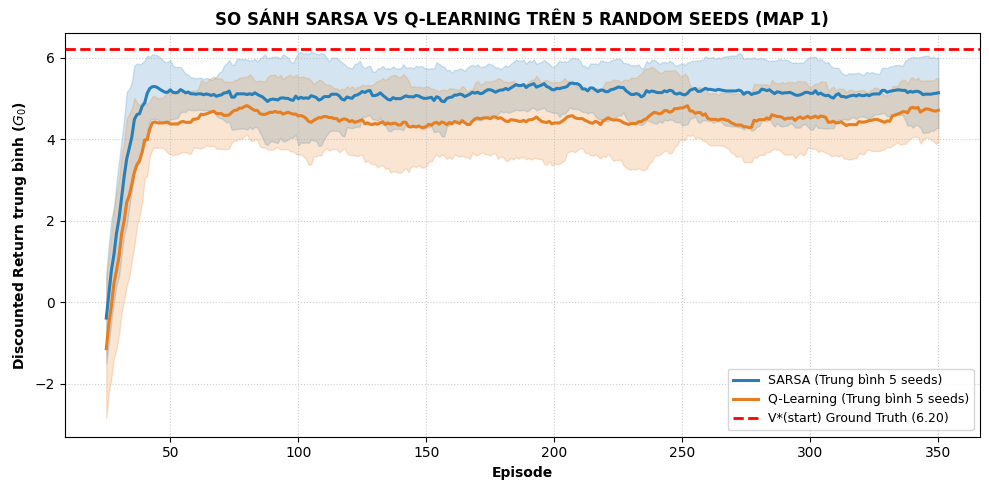

In [14]:
print("Đang huấn luyện SARSA và Q-Learning trên 5 Random Seeds...")
multi_res = run_multi_seed_experiment(seeds=[1, 2, 3, 4, 5], episodes=350)
fig = plot_multi_seed_comparison(
    {"SARSA": multi_res["SARSA"], "Q-Learning": multi_res["Q-Learning"]},
    ground_truth_v=multi_res["ground_truth_v"],
    window=25,
    title="SO SÁNH SARSA VS Q-LEARNING TRÊN 5 RANDOM SEEDS (MAP 1)"
)
plt.show()

### 3.4. Phân Tích Trường Hợp Thất Bại / Chậm Hội Tụ (Failure Case)

> **Hiện tượng:** Khi chu kỳ cổng lớn ($P=6$), nếu đặt $\varepsilon = 0.01$ (khám phá quá ít), Agent tìm thấy đường vòng đi được là lập tức bám lấy nó (Local Optimum), không bao giờ dám mạo hiểm bước vào cổng lúc đèn xanh!

In [15]:
fail_res = run_failure_case_analysis(episodes=500)
df_fail = pd.DataFrame([
    {"Hệ số khám phá epsilon": f"{fail_res['small_eps']['epsilon']}", "Số bước thực tế": fail_res['small_eps']['test_steps'], "Test Return": fail_res['small_eps']['test_return'], "Hiện tượng": fail_res['small_eps']['conclusion']},
    {"Hệ số khám phá epsilon": f"{fail_res['optimal_eps']['epsilon']}", "Số bước thực tế": fail_res['optimal_eps']['test_steps'], "Test Return": fail_res['optimal_eps']['test_return'], "Hiện tượng": fail_res['optimal_eps']['conclusion']},
])
display(df_fail)

,Hệ số khám phá epsilon,Số bước thực tế,Test Return,Hiện tượng
0,0.01,5,6.0,"Kẹt ở đường vòng! Tốn 5 bước, Return = 6.0 (Lo..."
1,0.2,6,5.0,Hội tụ về đường tối ưu qua cổng! Chỉ tốn 6 bướ...


### 3.5. Demo 1 Episode Hoàn Chỉnh Trên Bản Đồ Khó (Map 3: 6×6, Cấp 1 Vé Pass)
Chạy và ghi lại từng bước đi của Agent theo chính sách tối ưu vừa học được từ **Q-Learning** trên Map 3!

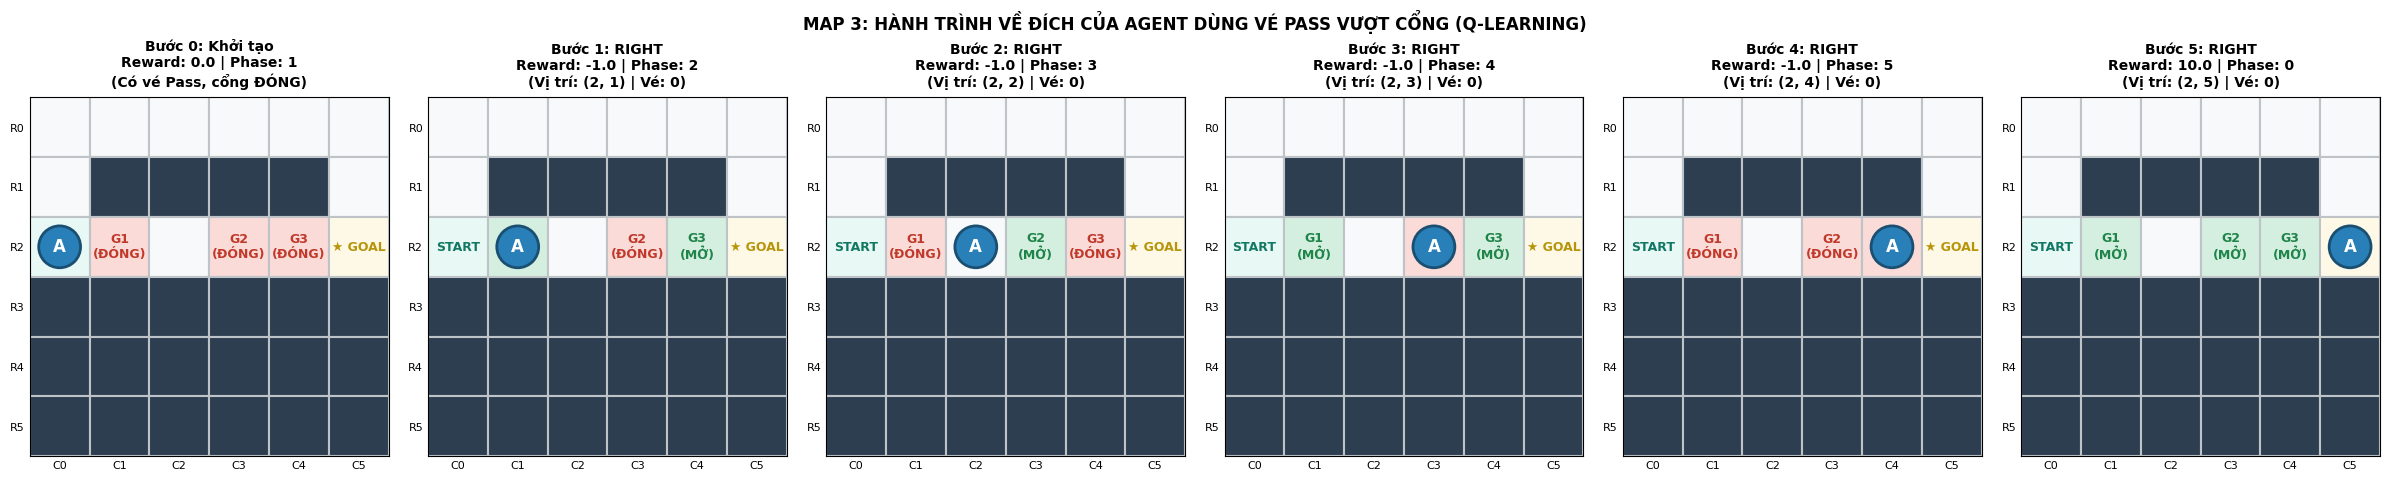

In [25]:
# Huấn luyện Q-Learning trên Map 3
env3_demo = make_env("map3")
res_map3 = q_learning(env3_demo, gamma=0.9, alpha=0.1, epsilon=0.15, episodes=700)

# Chạy 1 episode thực tế từ start
s, _ = env3_demo.reset(options={"start_phase": 1, "initial_pass": 1})
demo_frames = [{"env": copy.deepcopy(env3_demo), "action_name": "Khởi tạo", "reward": 0.0, "phase": 1, "note": "Có vé Pass, cổng ĐÓNG"}]

for step_idx in range(10):
    a = res_map3["policy"][s]
    s, r, term, trunc, _ = env3_demo.step(a)
    r_pos, c_pos, ph, p_av = env3_demo.decode_state(s)
    demo_frames.append({
        "env": copy.deepcopy(env3_demo),
        "action_name": ACTION_NAMES[a],
        "reward": r,
        "phase": ph,
        "note": f"Vị trí: ({r_pos}, {c_pos}) | Vé: {p_av}",
    })
    if term or trunc: break

# Vẽ chuỗi hình ảnh liên hoàn hành trình về đích
plot_progression(demo_frames, main_title="MAP 3: HÀNH TRÌNH VỀ ĐÍCH CỦA AGENT DÙNG VÉ PASS VƯỢT CỔNG (Q-LEARNING)")
plt.show()


In [20]:
from env import make_env, ACTION_NAMES
from algorithms import value_iteration

env = make_env("map1", render_mode="human")
policy = value_iteration(env)["policy"]

s, _ = env.reset(options={"start_phase": 1})
done = False
step = 0

print("Bấm phím [ENTER] trên bàn phím để xem từng bước đi tiếp theo...")
env.render()

while not done:
    input()  # Chờ bạn nhấn phím Enter mới chạy bước tiếp theo
    step += 1
    a = policy[s]
    next_s, r, term, trunc, _ = env.step(a)
    print(f"\n--- Bước {step}: Agent thực hiện [{ACTION_NAMES[a]}] | Điểm thưởng: {r} ---")
    env.render()
    s = next_s
    done = term or trunc

print("KẾT THÚC EPISODE!")

Bấm phím [ENTER] trên bàn phím để xem từng bước đi tiếp theo...
--- Map 1 (Dễ - 4x4) ---
Bước: 0/100 | Phase: 1/2 | Vé Pass: 0 | Vị trí: (2, 0) | State ID: 17
Cổng: G1@(2, 1):CLOSED
+---+---+---+---+
| . | . | . | . |
+---+---+---+---+
| . | # | # | . |
+---+---+---+---+
| A |G1:X| . | G |
+---+---+---+---+
| # | # | # | # |
+---+---+---+---+

--- Bước 1: Agent thực hiện [WAIT] | Điểm thưởng: -1.0 ---
--- Map 1 (Dễ - 4x4) ---
Bước: 1/100 | Phase: 0/2 | Vé Pass: 0 | Vị trí: (2, 0) | State ID: 16
Cổng: G1@(2, 1):OPEN
+---+---+---+---+
| . | . | . | . |
+---+---+---+---+
| . | # | # | . |
+---+---+---+---+
| A |G1:O| . | G |
+---+---+---+---+
| # | # | # | # |
+---+---+---+---+

--- Bước 2: Agent thực hiện [RIGHT] | Điểm thưởng: -1.0 ---
--- Map 1 (Dễ - 4x4) ---
Bước: 2/100 | Phase: 1/2 | Vé Pass: 0 | Vị trí: (2, 1) | State ID: 19
Cổng: G1@(2, 1):CLOSED
+---+---+---+---+
| . | . | . | . |
+---+---+---+---+
| . | # | # | . |
+---+---+---+---+
| S | A | . | G |
+---+---+---+---+
| # | # | #